# PRCP-1015: Earthquake Damage Prediction

## Problem Statement

Predicting the level of damage to buildings caused by the 2015 Gorkha earthquake in Nepal, based on aspects of building location, structure, and legal ownership.

**Tasks:**
1. Prepare a complete data analysis report on the given data.
2. Create a predictive model for the ordinal variable `damage_grade` (1 = low damage, 2 = medium damage, 3 = almost complete destruction).
3. Provide suggestions to seismologists / structural engineers to avoid earthquake events leading to significant damage in buildings.
4. Model comparison report.
5. Report on challenges faced.

## Objective

Build a model that predicts `damage_grade` for a building given its structural and location characteristics, identify the factors most strongly associated with severe damage, and translate those findings into actionable construction/planning recommendations.

## Dataset Description

- `train_values.csv`: 260,601 rows x 39 columns — building structure and legal ownership features. `building_id` is a unique random identifier.
- `train_labels.csv`: 260,601 rows x 2 columns — `building_id` and the target `damage_grade`.
- `geo_level_1_id`, `geo_level_2_id`, `geo_level_3_id`: geographic region, largest to most specific (31 / ~1,400 / ~11,600 unique values respectively).
- Structural features: `count_floors_pre_eq`, `age`, `area_percentage`, `height_percentage`, plus categorical construction attributes (`land_surface_condition`, `foundation_type`, `roof_type`, `ground_floor_type`, `other_floor_type`, `position`, `plan_configuration`, `legal_ownership_status` — categorical values are obfuscated single lowercase letters).
- 11 binary `has_superstructure_*` flags describing construction material.
- `count_families` and 10 binary `has_secondary_use_*` flags describing building usage.
- Target `damage_grade`: ordinal, 1 (low) / 2 (medium) / 3 (almost complete destruction).

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Data Loading

In [2]:
train_labels = pd.read_csv('train_labels.csv')

In [3]:
train_values = pd.read_csv('train_values.csv')

In [4]:
train_labels.head()

,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


In [5]:
train_labels.shape

(260601, 2)

In [6]:
train_values.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,...,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,...,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,...,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,...,0,0,0,0,0,0,0,0,0,0


In [7]:
train_values.shape

(260601, 39)

## Initial Data Understanding

In [8]:
train_labels.isnull().sum()

building_id     0
damage_grade    0
dtype: int64

In [9]:
train_values.isnull().sum()

building_id                               0
geo_level_1_id                            0
geo_level_2_id                            0
geo_level_3_id                            0
count_floors_pre_eq                       0
age                                       0
area_percentage                           0
height_percentage                         0
land_surface_condition                    0
foundation_type                           0
roof_type                                 0
ground_floor_type                         0
other_floor_type                          0
position                                  0
plan_configuration                        0
has_superstructure_adobe_mud              0
has_superstructure_mud_mortar_stone       0
has_superstructure_stone_flag             0
has_superstructure_cement_mortar_stone    0
has_superstructure_mud_mortar_brick       0
has_superstructure_cement_mortar_brick    0
has_superstructure_timber                 0
has_superstructure_bamboo       

In [10]:
train_labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   building_id   260601 non-null  int64
 1   damage_grade  260601 non-null  int64
dtypes: int64(2)
memory usage: 4.0 MB


In [11]:
train_values.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 39 columns):
 #   Column                                  Non-Null Count   Dtype 
---  ------                                  --------------   ----- 
 0   building_id                             260601 non-null  int64 
 1   geo_level_1_id                          260601 non-null  int64 
 2   geo_level_2_id                          260601 non-null  int64 
 3   geo_level_3_id                          260601 non-null  int64 
 4   count_floors_pre_eq                     260601 non-null  int64 
 5   age                                     260601 non-null  int64 
 6   area_percentage                         260601 non-null  int64 
 7   height_percentage                       260601 non-null  int64 
 8   land_surface_condition                  260601 non-null  object
 9   foundation_type                         260601 non-null  object
 10  roof_type                               260601 non-null 

In [12]:
train_values.dtypes[train_values.dtypes == "object"]

land_surface_condition    object
foundation_type           object
roof_type                 object
ground_floor_type         object
other_floor_type          object
position                  object
plan_configuration        object
legal_ownership_status    object
dtype: object

In [13]:
train_labels.describe()

,building_id,damage_grade
count,2.606010e+05,260601.000000
mean,5.256755e+05,2.238272
std,3.045450e+05,0.611814
min,4.000000e+00,1.000000
25%,2.611900e+05,2.000000
50%,5.257570e+05,2.000000
75%,7.897620e+05,3.000000
max,1.052934e+06,3.000000


In [14]:
train_values.describe()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,...,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
count,2.606010e+05,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,...,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000,260601.000000
mean,5.256755e+05,13.900353,701.074685,6257.876148,2.129723,26.535029,8.018051,5.434365,0.088645,0.761935,...,0.064378,0.033626,0.008101,0.000940,0.000361,0.001071,0.000188,0.000146,0.000088,0.005119
std,3.045450e+05,8.033617,412.710734,3646.369645,0.727665,73.565937,4.392231,1.918418,0.284231,0.425900,...,0.245426,0.180265,0.089638,0.030647,0.018989,0.032703,0.013711,0.012075,0.009394,0.071364
min,4.000000e+00,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,2.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.611900e+05,7.000000,350.000000,3073.000000,2.000000,10.000000,5.000000,4.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5.257570e+05,12.000000,702.000000,6270.000000,2.000000,15.000000,7.000000,5.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,7.897620e+05,21.000000,1050.000000,9412.000000,2.000000,30.000000,9.000000,6.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.052934e+06,30.000000,1427.000000,12567.000000,9.000000,995.000000,100.000000,32.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


## Merging Values and Labels, Target Variable Overview

In [15]:
df = train_values.merge(train_labels, on='building_id')
df.shape

(260601, 40)

In [16]:
df['damage_grade'].value_counts(normalize=True)

damage_grade
2    0.568912
3    0.334680
1    0.096408
Name: proportion, dtype: float64

In [17]:
df.duplicated().sum()

np.int64(0)

## Exploratory Data Analysis: Numeric Features vs Damage Grade

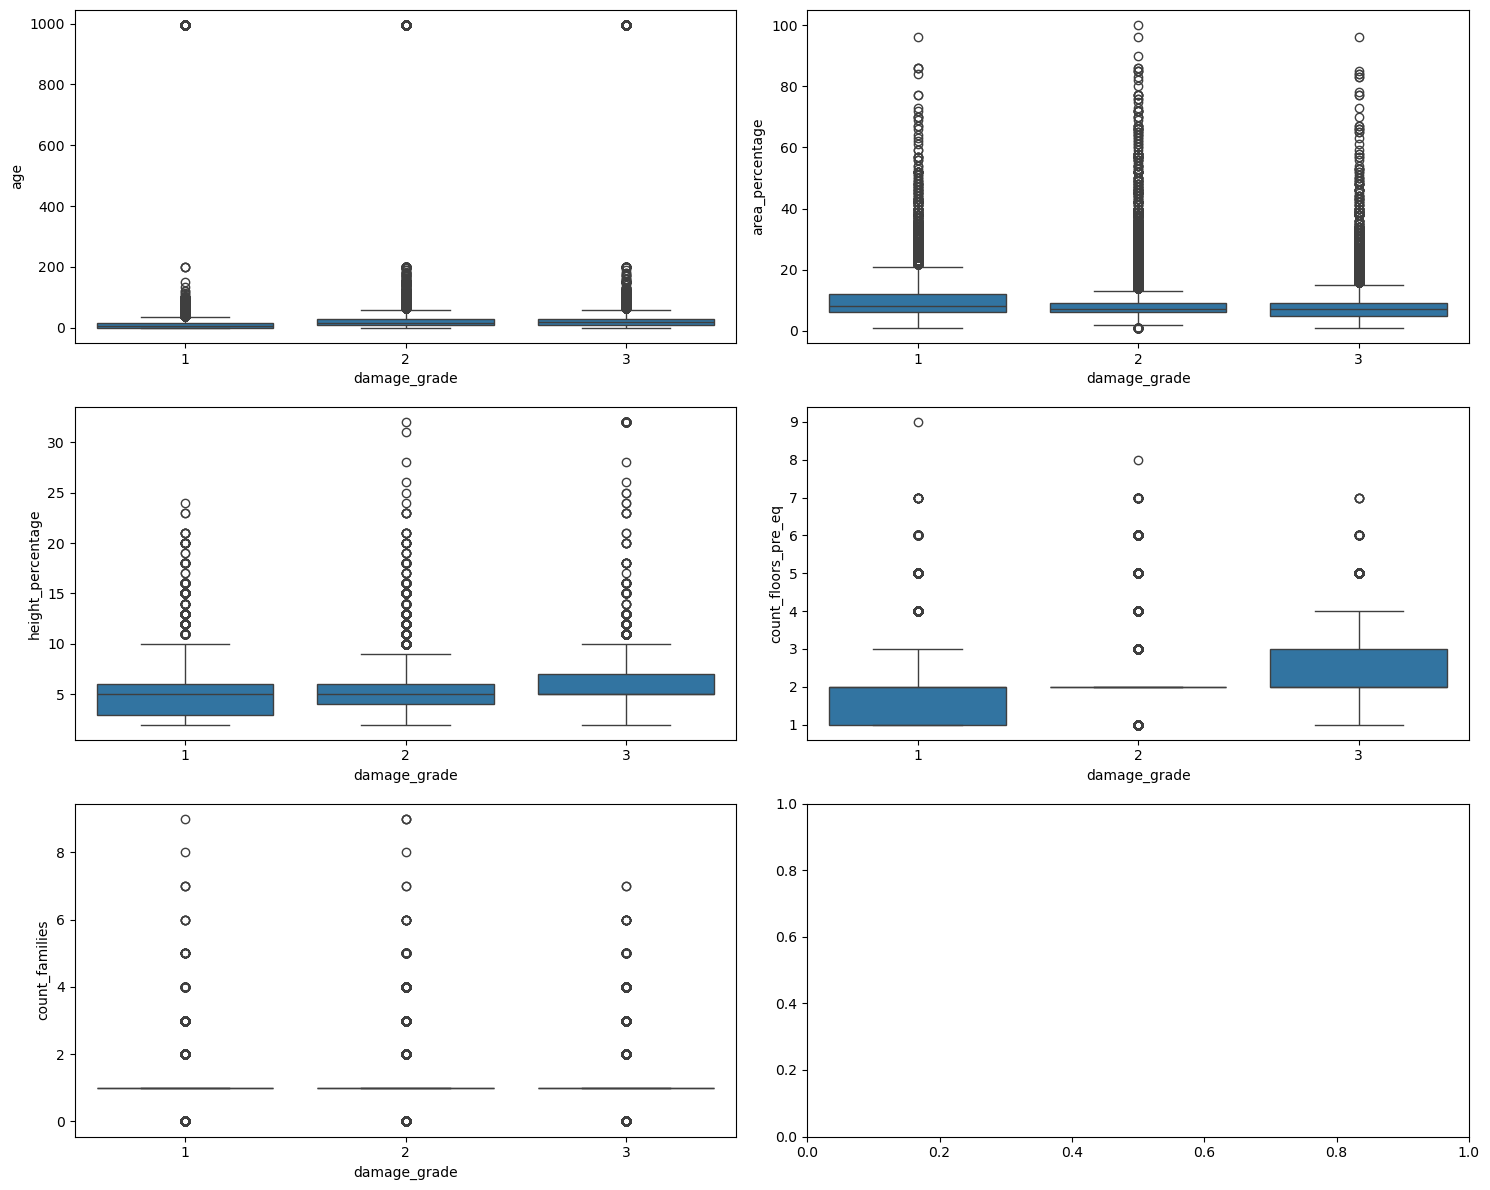

In [18]:
list1 = ['age', 'area_percentage', 'height_percentage', 'count_floors_pre_eq', 'count_families']
fig, axes = plt.subplots(3, 2, figsize=(15,12))
axes = axes.flatten()
for i , col in enumerate(list1):
    sns.boxplot(data=df,x="damage_grade",y=col,ax=axes[i])
plt.tight_layout()
plt.show()

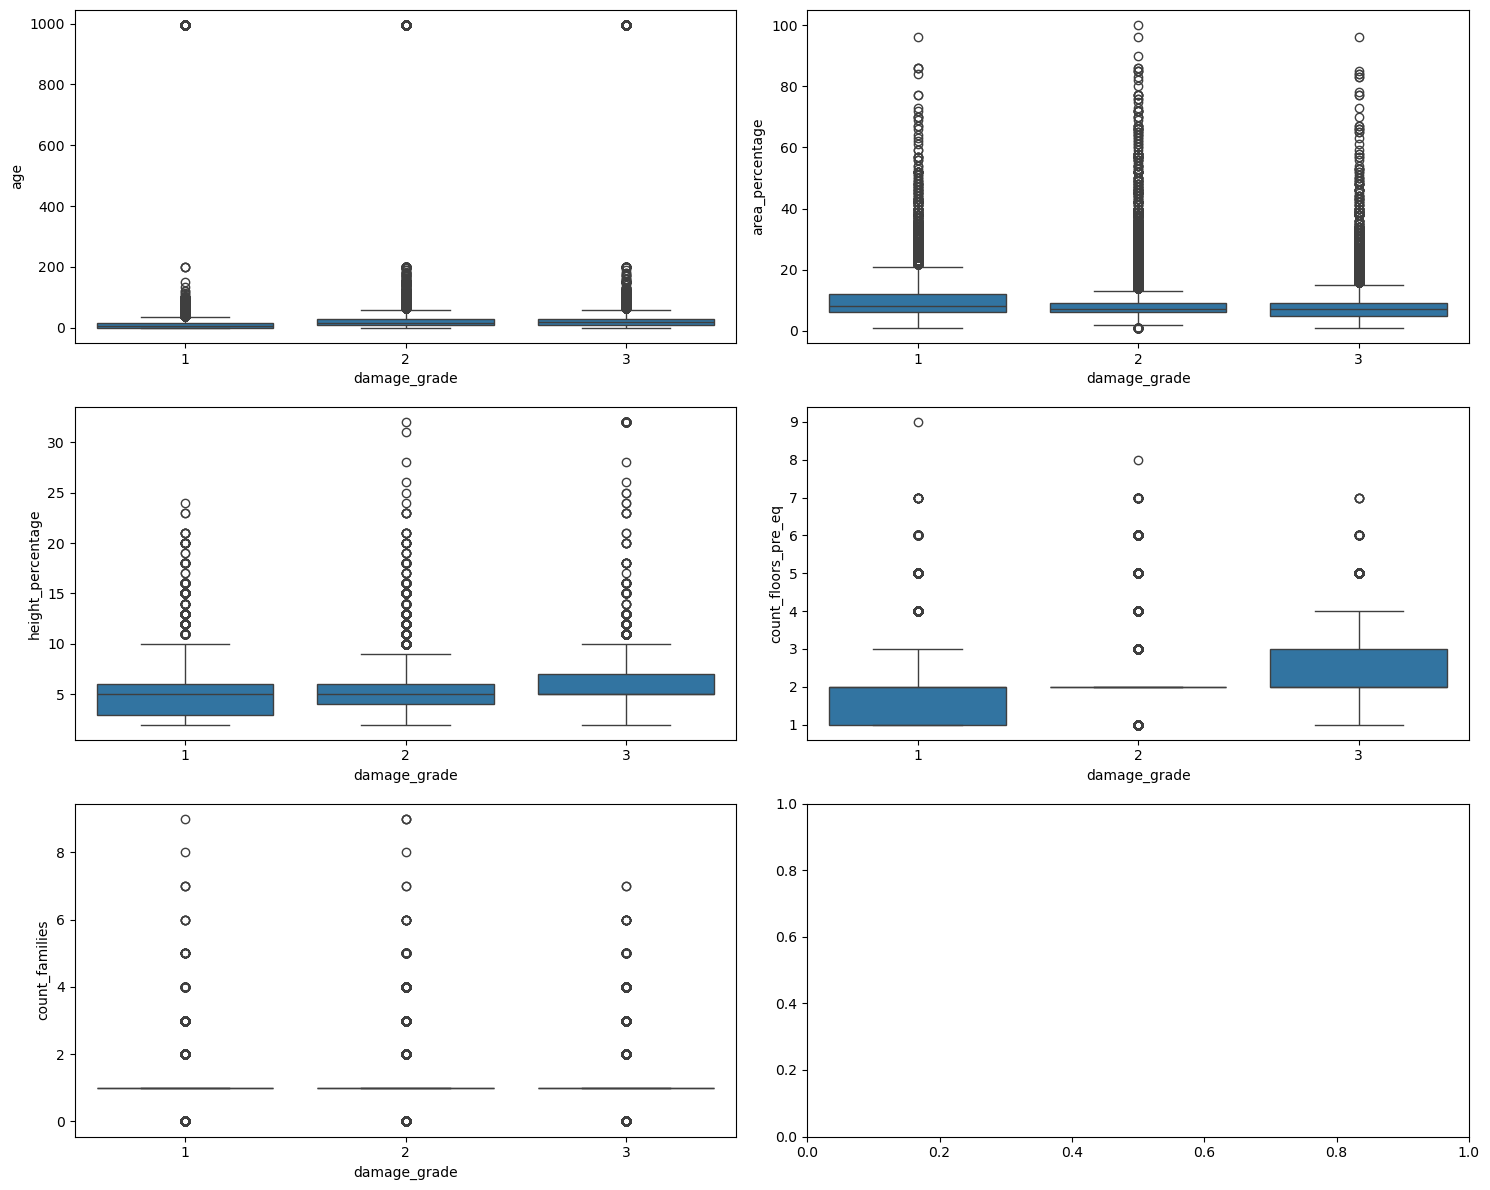

In [19]:
list1 = ['age', 'area_percentage', 'height_percentage', 'count_floors_pre_eq', 'count_families']
fig, axes = plt.subplots(3, 2, figsize=(15,12))
axes = axes.flatten()
for i , col in enumerate(list1):
    sns.boxplot(data=df,x="damage_grade",y=col,ax=axes[i])
plt.tight_layout()
plt.show()

### Handling the `age` Anomaly (Placeholder Value 995)

In [20]:
(df['age'] == 995).sum()

np.int64(1390)

In [21]:
df['AGE_ANOM'] = (df['age'] == 995).astype(int)

In [22]:
df['age'] = df['age'].replace(995, np.nan)
df['age'] = df['age'].fillna(df['age'].median())

In [23]:
df['age'].max()

200.0

## Exploratory Data Analysis: Categorical Features vs Damage Grade

### Foundation Type

In [24]:
pd.crosstab(df['foundation_type'], df['damage_grade'], normalize='index')

damage_grade,1,2,3
foundation_type,,,
h,0.247238,0.399862,0.352901
i,0.567539,0.411570,0.020890
r,0.048906,0.572615,0.378479
u,0.258696,0.598948,0.142356
w,0.287935,0.613176,0.098889


### Remaining Categorical Features

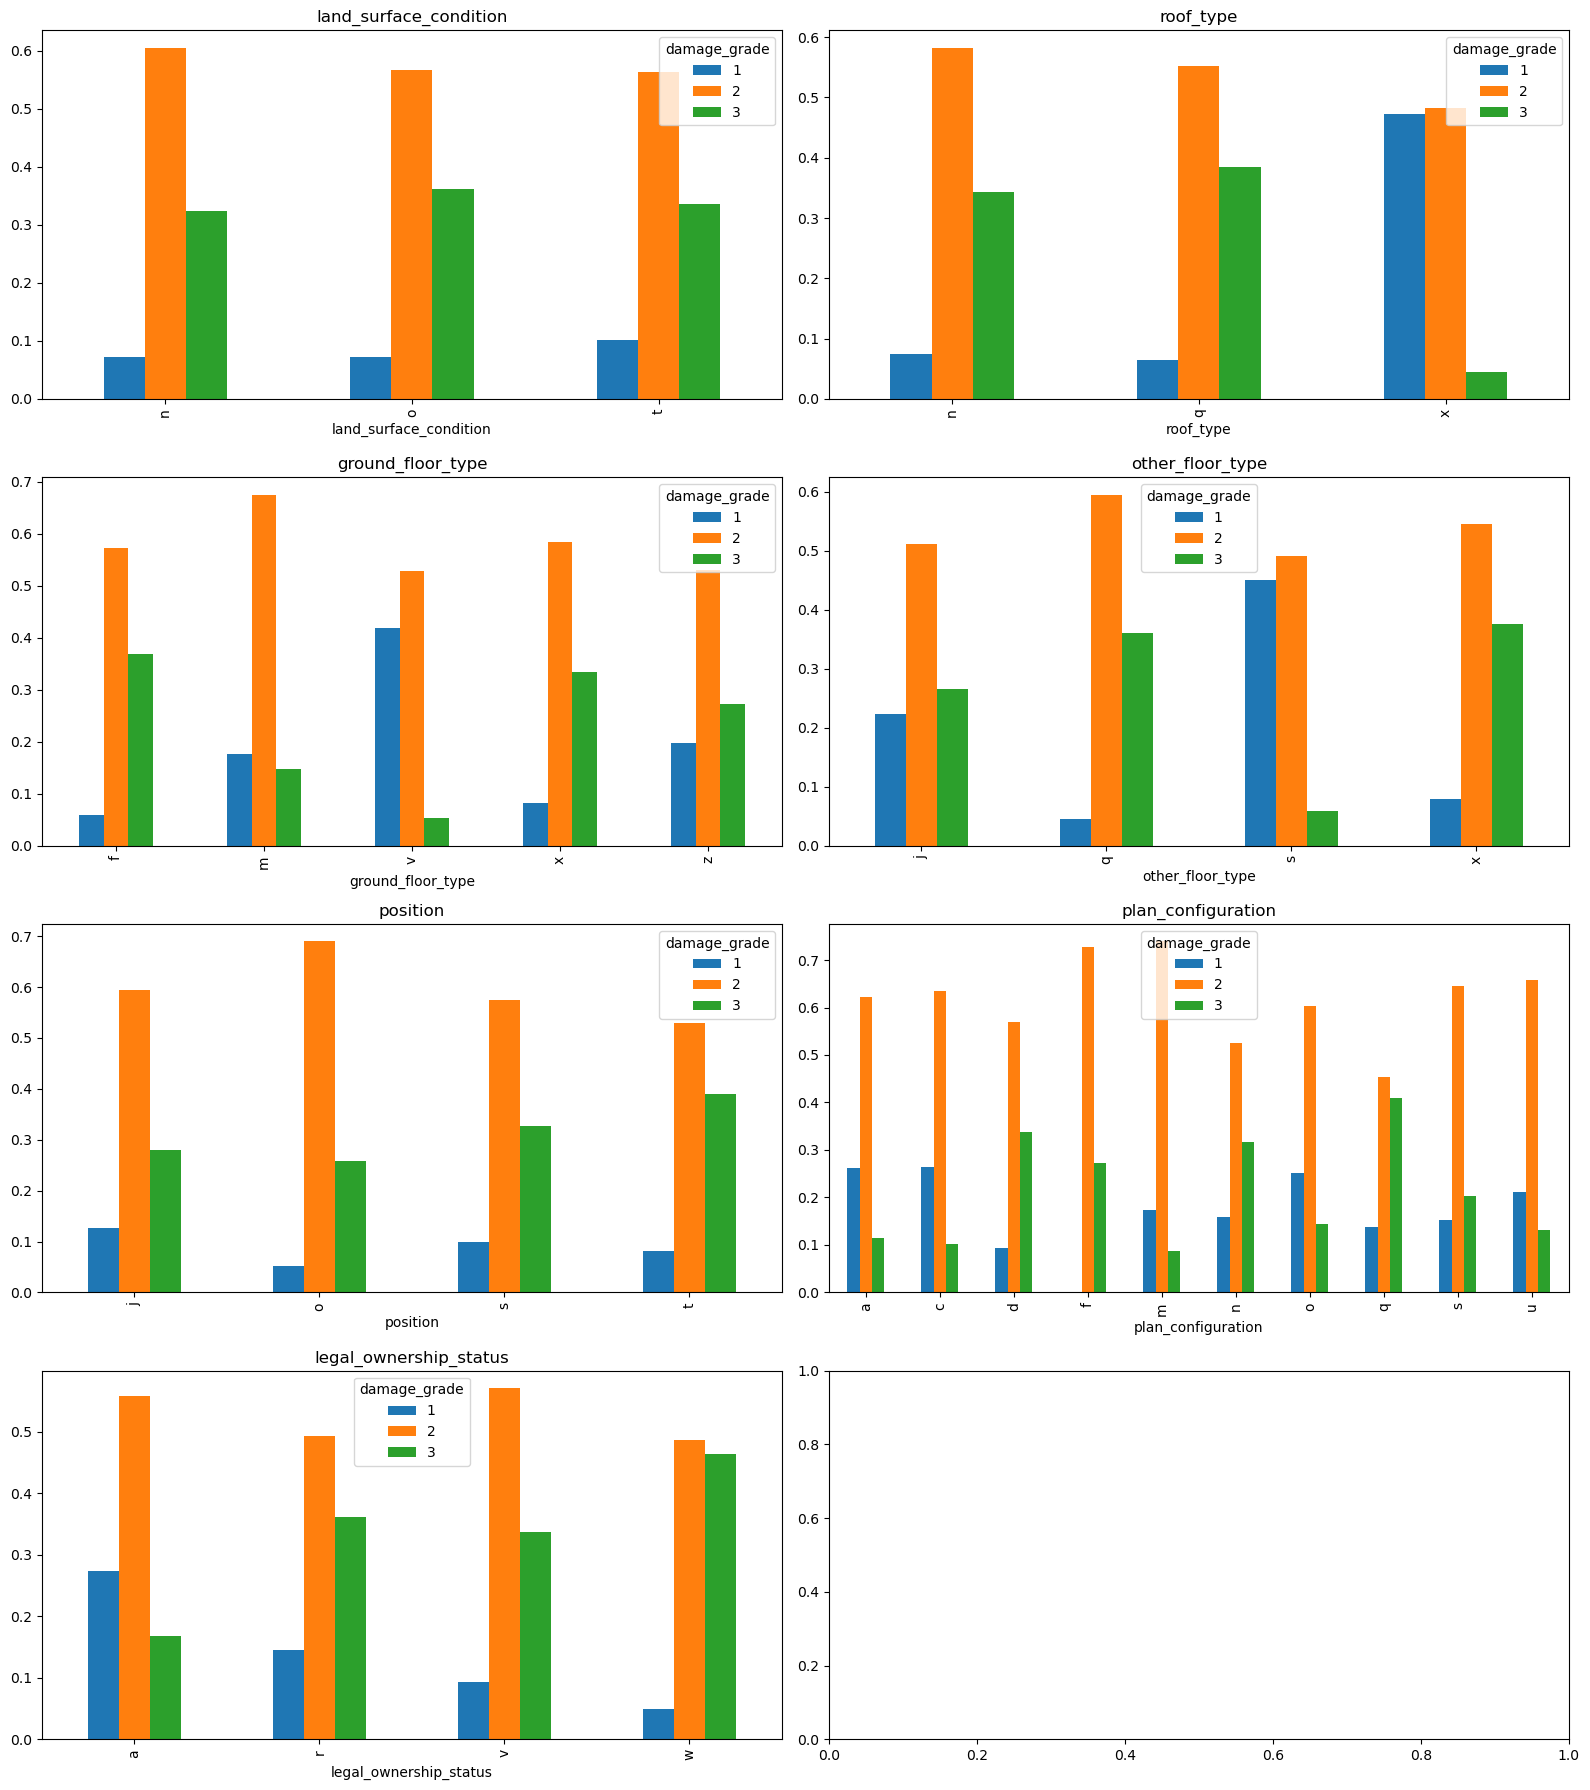

In [25]:
cat_cols = ['land_surface_condition', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']

fig, axes = plt.subplots(4, 2, figsize=(16, 18))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    pd.crosstab(df[col], df['damage_grade'], normalize='index').plot(kind='bar', ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

## Correlation Analysis

<Axes: >

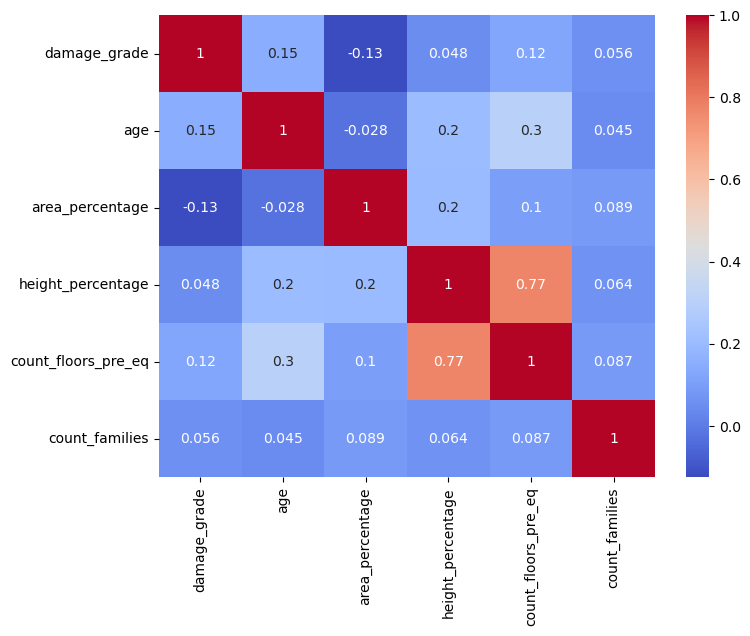

In [26]:
corr_cols = ['damage_grade', 'age', 'area_percentage', 'height_percentage', 'count_floors_pre_eq', 'count_families']
plt.figure(figsize=(8,6))
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm')

Text(0.5, 1.0, 'Average Damage by Superstructure Material')

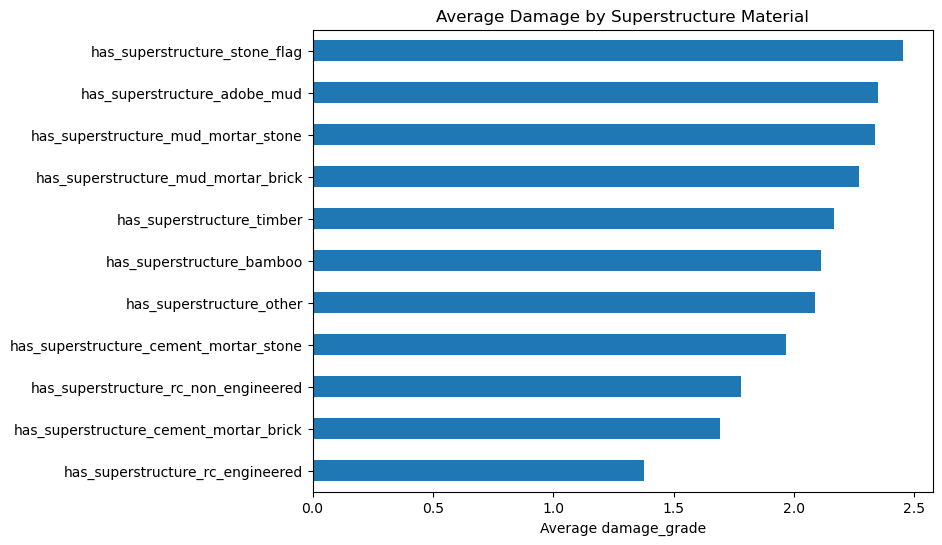

In [27]:
## Exploratory Data Analysis: Construction Material vs Average Damage

superstructure_cols = [col for col in df.columns if col.startswith('has_superstructure')]
material_avg_damage = {}
for col in superstructure_cols:
    material_avg_damage[col] = df[df[col] == 1]['damage_grade'].mean()

material_avg_damage = pd.Series(material_avg_damage).sort_values()
material_avg_damage.plot(kind='barh', figsize=(8,6))
plt.xlabel('Average damage_grade')
plt.title('Average Damage by Superstructure Material')

## Geographic Feature Cardinality Check

In [28]:
df[['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id']].nunique()

geo_level_1_id       31
geo_level_2_id     1414
geo_level_3_id    11595
dtype: int64

## Train-Test Split

In [29]:
from sklearn.model_selection import train_test_split
X = df.drop(['damage_grade', 'building_id'], axis=1)
y = df['damage_grade']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [30]:
X_train.shape

(208480, 39)

In [31]:
y_train.shape

(208480,)

In [32]:
X_test.shape

(52121, 39)

In [33]:
y_test.shape

(52121,)

## Feature Engineering: Geo-Level Target Encoding

`geo_level_2_id` (~1,400 categories) and `geo_level_3_id` (~11,600 categories) are too high-cardinality for one-hot encoding. Instead, each region is replaced with the mean `damage_grade` of buildings in that region, computed using **only the training set** (to avoid data leakage), then applied to both train and test. Regions in the test set not seen during training fall back to the overall training mean.

### `geo_level_2_id`

In [34]:
geo2_target_map = y_train.groupby(X_train['geo_level_2_id']).mean()

X_train['geo_level_2_encoded'] = X_train['geo_level_2_id'].map(geo2_target_map)
X_test['geo_level_2_encoded'] = X_test['geo_level_2_id'].map(geo2_target_map)

overall_mean = y_train.mean()
X_test['geo_level_2_encoded'] = X_test['geo_level_2_encoded'].fillna(overall_mean)

In [35]:
X_train.isnull().sum()

geo_level_1_id                            0
geo_level_2_id                            0
geo_level_3_id                            0
count_floors_pre_eq                       0
age                                       0
area_percentage                           0
height_percentage                         0
land_surface_condition                    0
foundation_type                           0
roof_type                                 0
ground_floor_type                         0
other_floor_type                          0
position                                  0
plan_configuration                        0
has_superstructure_adobe_mud              0
has_superstructure_mud_mortar_stone       0
has_superstructure_stone_flag             0
has_superstructure_cement_mortar_stone    0
has_superstructure_mud_mortar_brick       0
has_superstructure_cement_mortar_brick    0
has_superstructure_timber                 0
has_superstructure_bamboo                 0
has_superstructure_rc_non_engine

In [36]:
X_test['geo_level_2_encoded'].isnull().sum()

np.int64(0)

### `geo_level_3_id`

In [37]:
geo3_target_map = y_train.groupby(X_train['geo_level_3_id']).mean()

X_train['geo_level_3_encoded'] = X_train['geo_level_3_id'].map(geo3_target_map)
X_test['geo_level_3_encoded'] = X_test['geo_level_3_id'].map(geo3_target_map)

overall_mean = y_train.mean()
X_test['geo_level_3_encoded'] = X_test['geo_level_3_encoded'].fillna(overall_mean)

In [38]:
X_test['geo_level_3_encoded'].isnull().sum()

np.int64(0)

### Dropping Raw High-Cardinality IDs

In [39]:
X_train = X_train.drop(['geo_level_2_id', 'geo_level_3_id'], axis=1)
X_test = X_test.drop(['geo_level_2_id', 'geo_level_3_id'], axis=1)

## Categorical Encoding

Remaining text categoricals are one-hot encoded. Train and test are concatenated first and encoded together, then split back apart, to guarantee identical columns on both sides.

In [40]:
combined = pd.concat([X_train, X_test], axis=0)
combined = pd.get_dummies(combined, drop_first=True)

X_train = combined.iloc[:len(X_train)]
X_test = combined.iloc[len(X_train):]

In [41]:
X_train.shape

(208480, 61)

In [42]:
X_test.shape

(52121, 61)

## Model Setup: Initial Comparison (Class-Weighted)

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score

models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000),
    'Random Forest': RandomForestClassifier(class_weight='balanced', random_state=42),
    'LightGBM': LGBMClassifier(class_weight='balanced', random_state=42)
}

In [44]:
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    score = f1_score(y_test, preds, average='micro')
    results[name] = score
    print(name, score)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression 0.6845801116632452
Random Forest 0.7343105466126897
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.048217 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 800
[LightGBM] [Info] Number of data points in the train set: 208480, number of used features: 60
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
LightGBM 0.6876307054738013


## Revisiting Class Imbalance Handling

The micro-averaged F1 score used by this competition is mathematically equivalent to accuracy for a single-label multi-class problem — it does not specifically reward minority-class recall the way ROC-AUC did in the Home Loan Default project. `class_weight='balanced'` forces the model to pay equal attention to the rare Grade 1 class (9.6%), which can trade away majority-class (Grade 2, 57%) accuracy for a metric that doesn't reward that trade. Each model was re-tested **without** class weighting to check this empirically.

In [45]:
lgbm_unweighted = LGBMClassifier(random_state=42)
lgbm_unweighted.fit(X_train, y_train)
preds = lgbm_unweighted.predict(X_test)
score = f1_score(y_test, preds, average='micro')
print("LightGBM (no class weighting):", score)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.044384 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 800
[LightGBM] [Info] Number of data points in the train set: 208480, number of used features: 60
[LightGBM] [Info] Start training from score -2.339173
[LightGBM] [Info] Start training from score -0.564028
[LightGBM] [Info] Start training from score -1.094582
LightGBM (no class weighting): 0.7384739356497381


In [46]:
rf_unweighted = RandomForestClassifier(random_state=42)
rf_unweighted.fit(X_train, y_train)
preds = rf_unweighted.predict(X_test)
score = f1_score(y_test, preds, average='micro')
print("Random Forest (no class weighting):", score)

Random Forest (no class weighting): 0.7350971777210721


In [47]:
lr_unweighted = LogisticRegression(max_iter=1000)
lr_unweighted.fit(X_train, y_train)
preds = lr_unweighted.predict(X_test)
score = f1_score(y_test, preds, average='micro')
print("Logistic Regression (no class weighting):", score)

Logistic Regression (no class weighting): 0.7291302929721225


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Result:** all three models perform better unweighted on this dataset/metric combination:

| Model | Weighted (balanced) | Unweighted |
|---|---|---|
| Logistic Regression | 0.6833 | 0.7295 |
| Random Forest | 0.7343 | 0.7351 |
| LightGBM | 0.6876 | 0.7385 |

Unweighted LightGBM is the best model going into tuning. Random Forest changes the least between weighted/unweighted (naturally more imbalance-robust due to bagging); Logistic Regression and LightGBM are more sensitive to the weighting choice.

## Hyperparameter Tuning (LightGBM)

Tuned on a 30% subsample (to manage memory) using `RandomizedSearchCV`, optimizing directly for `f1_micro` — the competition's actual grading metric.

In [48]:
from sklearn.model_selection import RandomizedSearchCV

X_train_sample = X_train.sample(frac=0.3, random_state=42)
y_train_sample = y_train.loc[X_train_sample.index]

param_dist = {
    'num_leaves': [31, 63, 127],
    'learning_rate': [0.05, 0.1, 0.15],
    'n_estimators': [200, 300, 500],
    'max_depth': [-1, 10, 15]
}

lgbm_base = LGBMClassifier(random_state=42)  # no class_weight this time, per your findings

random_search = RandomizedSearchCV(
    estimator=lgbm_base,
    param_distributions=param_dist,
    n_iter=8,
    scoring='f1_micro',
    cv=3,
    random_state=42,
    n_jobs=2
)

random_search.fit(X_train_sample, y_train_sample)

print("Best params:", random_search.best_params_)
print("Best CV score:", random_search.best_score_)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.010867 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 767
[LightGBM] [Info] Number of data points in the train set: 62544, number of used features: 55
[LightGBM] [Info] Start training from score -2.351135
[LightGBM] [Info] Start training from score -0.563834
[LightGBM] [Info] Start training from score -1.091491
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further spli

## Final Model: Retrain on Full Data & Evaluate

In [49]:
final_lgbm = LGBMClassifier(
    num_leaves=63,
    n_estimators=200,
    max_depth=10,
    learning_rate=0.05,
    random_state=42
)

final_lgbm.fit(X_train, y_train)
final_preds = final_lgbm.predict(X_test)
final_score = f1_score(y_test, final_preds, average='micro')
print("Final tuned LightGBM test score:", final_score)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.025184 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 800
[LightGBM] [Info] Number of data points in the train set: 208480, number of used features: 60
[LightGBM] [Info] Start training from score -2.339173
[LightGBM] [Info] Start training from score -0.564028
[LightGBM] [Info] Start training from score -1.094582
Final tuned LightGBM test score: 0.7397402198729879


## Feature Importance Analysis

In [50]:
importances = final_lgbm.feature_importances_
feature_importance = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)
feature_importance.head(15)

geo_level_3_encoded                       6665
geo_level_2_encoded                       5869
geo_level_1_id                            3682
age                                       3424
area_percentage                           2983
height_percentage                         1859
count_families                            1019
count_floors_pre_eq                        972
has_superstructure_mud_mortar_stone        714
has_superstructure_cement_mortar_brick     563
has_secondary_use                          477
other_floor_type_q                         475
ground_floor_type_v                        473
roof_type_q                                471
has_superstructure_timber                  407
dtype: int32

## Reports

### EDA Report

**Dataset Overview**
- 260,601 buildings, 39 structural/location features plus the ordinal target `damage_grade` (1 = low, 2 = medium, 3 = almost complete destruction).
- Zero missing values in either `train_values.csv` or `train_labels.csv` — a much cleaner starting point than a typical real-world dataset.
- No duplicate rows.
- Target distribution: Grade 2 = 56.9%, Grade 3 = 33.5%, Grade 1 = 9.6% — moderately imbalanced, but far less extreme than a typical fraud/default dataset.

**Data Quality Issues Found**
- `age` contained a placeholder value of 995 (implausible building age) in 1,390 rows (~0.5% of data). Flagged with an `AGE_ANOM` indicator column, then replaced with NaN and median-imputed (max age afterward: a plausible 200 years).

**Key Findings — Numeric Features vs Damage Grade**
- `count_floors_pre_eq` and `height_percentage`: Grade 3 buildings skew toward more floors / greater height than Grade 1/2 — taller, multi-floor buildings show more severe damage, structurally plausible.
- `age`: mild positive correlation with damage (+0.15) — older buildings sustain somewhat more damage.
- `area_percentage`: mild negative correlation (-0.13) — larger building footprint is mildly protective.
- `count_families`: no meaningful differentiation across damage grades.
- Note: `height_percentage` and `count_floors_pre_eq` correlate 0.77 with each other (expected multicollinearity, not an issue for the tree-based models used).

**Key Findings — Categorical Features vs Damage Grade**
- `foundation_type`: strong signal — type `i` is the safest (56.8% Grade 1, only 2.1% Grade 3); type `r` is the riskiest (4.9% Grade 1, 37.8% Grade 3).
- `roof_type`: type `x` shows markedly less Grade 3 damage (~5%) than types `n`/`q`.
- `ground_floor_type`: type `v` is safest; other types show meaningfully more Grade 3 damage.
- `other_floor_type`: type `s` is safest; type `q` is riskiest.
- `position`: type `j` safest, type `o` riskiest (moderate differentiation).
- `legal_ownership_status`: type `a` safest; type `w` riskiest (Grade 2/3 nearly equal).
- `land_surface_condition` and `plan_configuration`: comparatively weak/flat differentiators.

**Construction Material Findings**
Average `damage_grade` by superstructure material shows a clean gradient: buildings using traditional materials (stone, adobe/mud, mud mortar, timber, bamboo) show the highest average damage; buildings using engineered materials (cement mortar brick, engineered reinforced concrete) show the lowest. This is the strongest single finding for the seismologist recommendations below.

**Geographic Findings**
`geo_level_2_id` and `geo_level_3_id` (fine-grained location) turned out to be, by a wide margin, the most predictive features in the final model — confirming that *where* a building is located (soil conditions, local shaking intensity) matters more than any single structural attribute measured here.

### Model Comparison Report

**Preprocessing for Modeling**
- Train/test split: 80/20, stratified on `damage_grade`.
- `geo_level_2_id`/`geo_level_3_id` target-encoded (mean `damage_grade` per region, computed on training data only, to avoid leakage) — raw high-cardinality IDs dropped afterward. `geo_level_1_id` (31 categories) kept as-is.
- Remaining 8 text categoricals one-hot encoded (`pd.get_dummies`, `drop_first=True`), encoded jointly across train+test to guarantee matching columns, then split back apart.
- Final feature set: 60 columns.

**Metric Choice**
This is a real DrivenData competition ("Richter's Predictor: Modeling Earthquake Damage"), graded on **micro-averaged F1 score** — the same metric used here, for results that are directly comparable to the public leaderboard. For reference, the actual competition's #1 leaderboard score is 0.7558, with top-1% solutions clustering around 0.75; a documented Random Forest solution reached 0.7273. These figures indicate a practical ceiling for this dataset — a much higher score (e.g. 90%+) is not achievable given the information available in these features alone.

**Models Trained**

| Model | Micro-F1 (test set) |
|---|---|
| Logistic Regression (unweighted) | 0.7295 |
| Random Forest (unweighted) | 0.7351 |
| LightGBM (unweighted) | 0.7385 |
| LightGBM (tuned) | **0.7397** |

**Recommendation**
The tuned, unweighted LightGBM model is recommended for production. Its test score (0.7397) is competitive with top-1% solutions on the actual competition leaderboard. Notably, `class_weight='balanced'` was found to *hurt* performance on this dataset for this metric — an imbalance-correction technique that is often beneficial elsewhere did not help here, since micro-F1 for single-label multi-class problems is equivalent to accuracy, and rewards majority-class correctness rather than minority-class recall.

**Feature Importance**
Top features: `geo_level_3_encoded`, `geo_level_2_encoded`, `geo_level_1_id` (location dominates), followed by `age`, `area_percentage`, `height_percentage`, `count_families`, `count_floors_pre_eq`, and construction-material/floor-type features (`has_superstructure_mud_mortar_stone`, `has_superstructure_cement_mortar_brick`, `ground_floor_type_v`, `roof_type_q`, `has_superstructure_timber`) — closely matching the manual EDA findings above.

### Challenges Report

1. **`age` anomaly:** A placeholder value of 995 appeared in ~0.5% of rows. Flagged with a binary indicator column before replacing with NaN and median-imputing, following the same pattern used for `DAYS_EMPLOYED` in the Home Loan Default project.

2. **High-cardinality geographic features:** `geo_level_2_id` (~1,400 categories) and `geo_level_3_id` (~11,600 categories) were far too high-cardinality for one-hot encoding. Resolved with target (mean) encoding, computed strictly on the training split to avoid data leakage, with an overall-mean fallback for any region unseen during training.

3. **Train/test column consistency after encoding:** One-hot encoding train and test separately risks mismatched columns if a category appears in only one split. Resolved by concatenating train and test, encoding jointly, then splitting back apart by row count.

4. **Class imbalance handling was not universally beneficial:** Unlike the Home Loan Default project, applying `class_weight='balanced'` *reduced* performance here for every model tested, since the competition's micro-F1 metric is equivalent to accuracy and does not specifically reward minority-class recall. This was verified empirically (weighted vs. unweighted for all 3 models) rather than assumed, and is reported as a genuine finding: imbalance correction should be evaluated against the actual metric being optimized, not applied by default.

5. **Realistic performance ceiling:** Initial results were compared against an assumed 90%+ target. Research into the actual DrivenData competition leaderboard (#1 = 0.7558 micro-F1, top-1% ≈ 0.75) showed this ceiling is a property of the dataset itself (ground-truth damage depends on physical factors like localized shaking intensity that are only partially captured by these 38 features), not a modeling shortfall. The final model (0.7397) sits close to top-1% territory on the real competition leaderboard.

6. **Memory constraints during tuning:** Full-dataset `RandomizedSearchCV` risked the same memory issues encountered previously. Resolved by tuning on a 30% subsample with reduced parallelism, then retraining the best parameters on the full training set before final evaluation.

### Suggestions to Seismologists / Structural Engineers

Based on the EDA and feature importance findings above:

1. **Prioritize construction material upgrades.** Buildings using traditional materials (mud, stone, bamboo, timber) show consistently and substantially higher damage than those using engineered materials (reinforced concrete, cement mortar brick). Retrofitting or phasing out traditional-material construction in earthquake-prone zones would likely have the single largest impact on reducing damage.

2. **Target foundation type `r` for reinforcement.** This foundation type showed by far the highest rate of severe (Grade 3) damage (37.8%) and the lowest rate of minimal damage (4.9%) of any foundation category — a clear, specific target for structural reinforcement programs or stricter building codes going forward.

3. **Review height and floor-count guidance.** Taller buildings and those with more pre-existing floors sustained more severe damage. Building codes in high-risk zones should consider stricter height/floor limits, or mandate additional structural reinforcement for multi-story buildings.

4. **Focus retrofitting resources geographically.** Location (`geo_level_2_id`/`geo_level_3_id`) was the single strongest predictor of damage in the model — more predictive than any individual structural attribute. This suggests some regions face materially higher earthquake risk (likely due to soil composition or proximity to the fault line) regardless of construction quality, and retrofitting/awareness resources would be most effectively concentrated in the highest-risk regions identified by this analysis, rather than spread evenly.

5. **Building age matters, but less than material and location.** Older buildings showed mildly elevated damage; age-based retrofitting policy is reasonable but should be secondary to the material and geographic targeting above, given the relative feature importance found.